# 01 — Exploratory Data Analysis

> **Purpose** — Understand the CTI dataset: size, class balance, temporal spread, text characteristics, and potential data quality issues before building models.

<span class="badge badge-blue">EDA</span><span class="badge badge-green">Data Quality</span><span class="badge badge-orange">Visualization</span>

## Table of Contents

1. [Setup & Imports](#1-setup--imports)
2. [Load Dataset](#2-load-dataset)
3. [Basic Info & Shape](#3-basic-info--shape)
4. [Missing Values & Duplicates](#4-missing-values--duplicates)
5. [Class Distribution](#5-class-distribution)
6. [Temporal Coverage](#6-temporal-coverage)
7. [Text Length Analysis](#7-text-length-analysis)
8. [Top Terms per Class](#8-top-terms-per-class)
9. [Word Clouds](#9-word-clouds)
10. [Key Observations](#10-key-observations)


## 1. Setup & Imports

In [1]:
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from src.config import DATASET_FILE, FIGURES_DIR

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 150

print('Dataset path:', DATASET_FILE)
print('Figures dir :', FIGURES_DIR)

Dataset path: D:\Projects\done\thesis\Implementation\dataset\synthetic_cti_reports.csv
Figures dir : D:\Projects\done\thesis\Implementation\output\figures


## 2. Load Dataset

In [2]:
df = pd.read_csv(DATASET_FILE)
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.to_period('M').astype(str)

print('Loaded:', df.shape)
df.head()

Loaded: (10000, 18)


,id,title,text,category,date,source,url,severity,threat_actor,malware,attack_vector,target_sector,country,cve_id,mitre_technique,mitre_technique_name,indicators,month
0,3568,DDoS activity targeting Retail organizations,A recent threat campaign involved ddos activit...,DDoS,2021-01-01,CTI-Source-6,https://cti-reports.example.org/report/3568,High,BlackOrchid,SilverWorm,Drive-by Download,Retail,Japan,CVE-2022-39414,T1059,Command and Scripting Interpreter,IP=111.96.63.206; DOMAIN=wall-west.net; SHA256...,2021-01
1,5617,Web Attack activity targeting Financial Servic...,A medium web attack campaign targeted organiza...,Web Attack,2021-01-01,CTI-Source-9,https://cti-reports.example.org/report/5617,Medium,DarkHydra,DarkLoader,Brute Force,Financial Services,United States,CVE-2024-29220,T1053,Scheduled Task/Job,IP=150.80.211.45; DOMAIN=austin-moreno.net; SH...,2021-01
2,2016,Credential Theft activity targeting Retail org...,A high credential theft campaign targeted orga...,Credential Theft,2021-01-01,CTI-Source-11,https://cti-reports.example.org/report/2016,High,StormByte,SilverWorm,Exposed Service,Retail,Australia,CVE-2026-54394,T1566.001,Spearphishing Attachment,IP=143.178.240.66; DOMAIN=briggs.org; SHA256=f...,2021-01
3,4000,Credential Theft activity targeting Government...,A recent threat campaign involved credential t...,Credential Theft,2021-01-01,CTI-Source-2,https://cti-reports.example.org/report/4000,Critical,NightWolf,RedLineX,Exposed Service,Government,United States,CVE-2026-60798,T1059,Command and Scripting Interpreter,IP=46.62.120.64; DOMAIN=williams.com; SHA256=3...,2021-01
4,1066,Phishing activity targeting Banking organizations,A high phishing campaign targeted organization...,Phishing,2021-01-01,CTI-Source-1,https://cti-reports.example.org/report/1066,High,APT-Alpha,ShadowRAT,Brute Force,Banking,India,CVE-2023-68334,T1083,File and Directory Discovery,IP=33.169.134.207; DOMAIN=holmes-matthews.org;...,2021-01


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id                    10000 non-null  int64         
 1   title                 10000 non-null  object        
 2   text                  10000 non-null  object        
 3   category              10000 non-null  object        
 4   date                  10000 non-null  datetime64[ns]
 5   source                10000 non-null  object        
 6   url                   10000 non-null  object        
 7   severity              10000 non-null  object        
 8   threat_actor          10000 non-null  object        
 9   malware               10000 non-null  object        
 10  attack_vector         10000 non-null  object        
 11  target_sector         10000 non-null  object        
 12  country               10000 non-null  object        
 13  cve_id           

## 3. Basic Info & Shape

In [4]:
n_rows, n_cols = df.shape
n_categories  = df['category'].nunique()
date_min      = df['date'].min().date()
date_max      = df['date'].max().date()
n_months      = df['month'].nunique()
n_sources     = df['source'].nunique() if 'source' in df.columns else 0

print(f'Rows           : {n_rows}')
print(f'Columns        : {n_cols}')
print(f'Categories     : {n_categories}')
print(f'Date range     : {date_min} -> {date_max}')
print(f'Months covered : {n_months}')
print(f'Sources        : {n_sources}')
print(f'Columns        : {list(df.columns)}')

Rows           : 10000
Columns        : 18
Categories     : 10
Date range     : 2021-01-01 -> 2026-09-01
Months covered : 69
Sources        : 15
Columns        : ['id', 'title', 'text', 'category', 'date', 'source', 'url', 'severity', 'threat_actor', 'malware', 'attack_vector', 'target_sector', 'country', 'cve_id', 'mitre_technique', 'mitre_technique_name', 'indicators', 'month']


## 4. Missing Values & Duplicates

In [5]:
missing = df.isnull().sum()
missing = missing[missing > 0]
print('Missing values per column:')
print(missing if len(missing) else '  (none)')

dup_text = df.duplicated(subset=['text']).sum()
dup_full = df.duplicated().sum()
print(f'\nDuplicate text rows : {dup_text}')
print(f'Duplicate full rows : {dup_full}')

Missing values per column:
  (none)

Duplicate text rows : 0
Duplicate full rows : 0


<div class="callout"><b>Data quality note:</b> If duplicates exist, they should be removed in the preprocessing step (<code>02_preprocessing.ipynb</code>) to prevent leakage and bias in the classifiers.</div>

## 5. Class Distribution

In [6]:
class_counts = df['category'].value_counts()
class_pct    = (class_counts / len(df) * 100).round(2)

summary = pd.DataFrame({
    'Count': class_counts,
    'Percent': class_pct,
})
summary

,Count,Percent
Ransomware,1041,10.41
Web Attack,1040,10.40
DDoS,1027,10.27
Vulnerability,1020,10.20
Credential Theft,993,9.93
Data Breach,990,9.90
Botnet,987,9.87
Malware,986,9.86
Phishing,983,9.83
Insider Threat,933,9.33


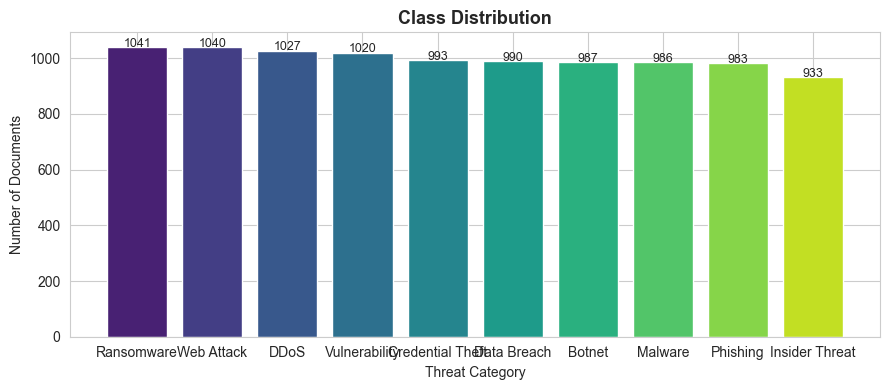

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = sns.color_palette('viridis', len(class_counts))
bars = ax.bar(class_counts.index, class_counts.values, color=colors)
ax.set_title('Class Distribution', fontsize=13, fontweight='bold')
ax.set_xlabel('Threat Category')
ax.set_ylabel('Number of Documents')

for bar, v in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 1, str(v),
            ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_class_distribution.png')
plt.show()

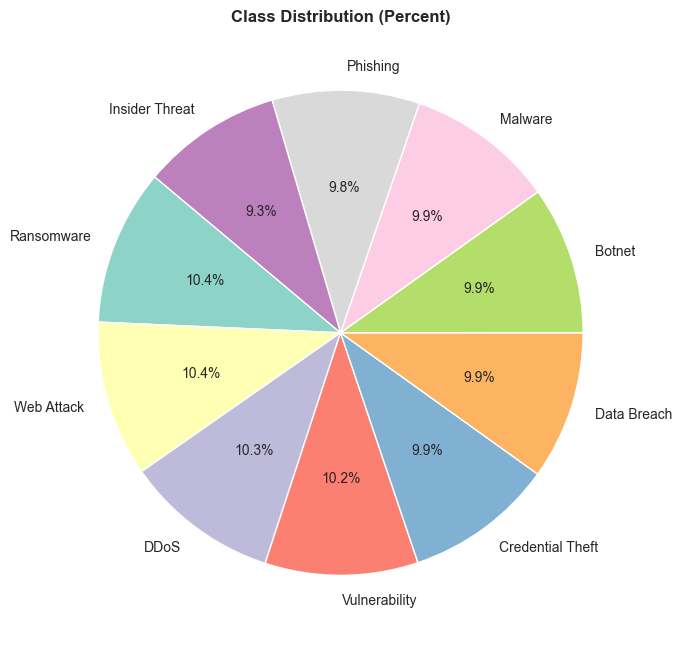

In [8]:
plt.figure(figsize=(7, 7))
plt.pie(class_counts.values, labels=class_counts.index,
        autopct='%1.1f%%', startangle=140,
        colors=sns.color_palette('Set3', len(class_counts)))
plt.title('Class Distribution (Percent)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_class_pie.png')
plt.show()

### Class Imbalance Check

In [9]:
maj = class_counts.max()
mnr = class_counts.min()
ratio = round(maj / mnr, 2)
print(f'Majority class : {class_counts.idxmax()} ({maj})')
print(f'Minority class : {class_counts.idxmin()} ({mnr})')
print(f'Imbalance ratio: {ratio}:1')
if ratio < 2:
    print('-> Balanced dataset.')
else:
    print('-> Imbalanced. Use macro-F1 in evaluation.')

Majority class : Ransomware (1041)
Minority class : Insider Threat (933)
Imbalance ratio: 1.12:1
-> Balanced dataset.


## 6. Temporal Coverage

In [10]:
monthly = df.groupby(['month', 'category']).size().unstack(fill_value=0)
print('Monthly counts per category:')
monthly.head()

Monthly counts per category:


category,Botnet,Credential Theft,DDoS,Data Breach,Insider Threat,Malware,Phishing,Ransomware,Vulnerability,Web Attack
month,,,,,,,,,,
2021-01,15,14,9,11,18,16,15,13,15,13
2021-02,13,10,18,12,12,9,14,14,17,16
2021-03,18,12,13,21,17,14,16,12,18,14
2021-04,12,15,21,11,9,10,11,12,20,14
2021-05,17,17,11,13,11,14,13,12,15,10


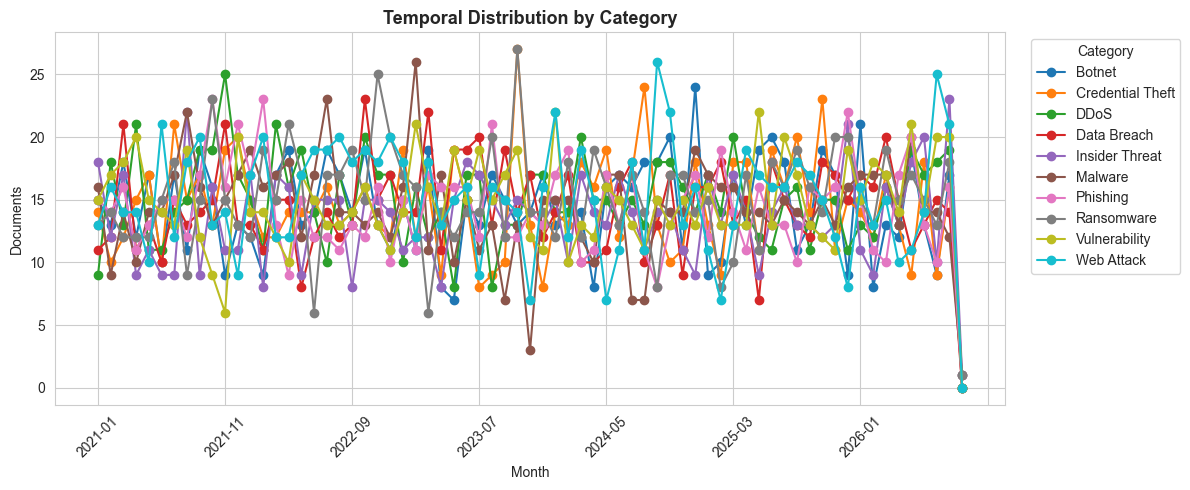

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))
monthly.plot(ax=ax, marker='o', linewidth=1.5)
ax.set_title('Temporal Distribution by Category', fontsize=13, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Documents')
plt.xticks(rotation=45)
plt.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_temporal_distribution.png')
plt.show()

In [12]:
monthly_total = df.groupby('month').size()
print('Total documents per month:')
print(monthly_total.to_string())

Total documents per month:
month
2021-01    139
2021-02    135
2021-03    155
2021-04    135
2021-05    133
2021-06    129
2021-07    151
2021-08    156
2021-09    158
2021-10    160
2021-11    151
2021-12    154
2022-01    151
2022-02    143
2022-03    151
2022-04    150
2022-05    141
2022-06    138
2022-07    158
2022-08    149
2022-09    140
2022-10    168
2022-11    159
2022-12    144
2023-01    149
2023-02    151
2023-03    149
2023-04    123
2023-05    140
2023-06    160
2023-07    140
2023-08    147
2023-09    133
2023-10    167
2023-11    125
2023-12    136
2024-01    158
2024-02    142
2024-03    145
2024-04    130
2024-05    147
2024-06    144
2024-07    152
2024-08    130
2024-09    148
2024-10    158
2024-11    132
2024-12    160
2025-01    143
2025-02    127
2025-03    151
2025-04    148
2025-05    138
2025-06    155
2025-07    160
2025-08    151
2025-09    138
2025-10    158
2025-11    145
2025-12    156
2026-01    154
2026-02    129
2026-03    160
2026-04    135
2026-05

## 7. Text Length Analysis

In [13]:
df['text_len']  = df['text'].astype(str).str.len()
df['word_cnt']  = df['text'].astype(str).str.split().str.len()

print('Character length stats:')
print(df['text_len'].describe().round(1))
print('\nWord count stats:')
print(df['word_cnt'].describe().round(1))

Character length stats:
count    10000.0
mean       484.0
std         20.1
min        434.0
25%        469.0
50%        481.0
75%        496.0
max        548.0
Name: text_len, dtype: float64

Word count stats:
count    10000.0
mean        59.9
std          3.2
min         55.0
25%         58.0
50%         59.0
75%         61.0
max         70.0
Name: word_cnt, dtype: float64


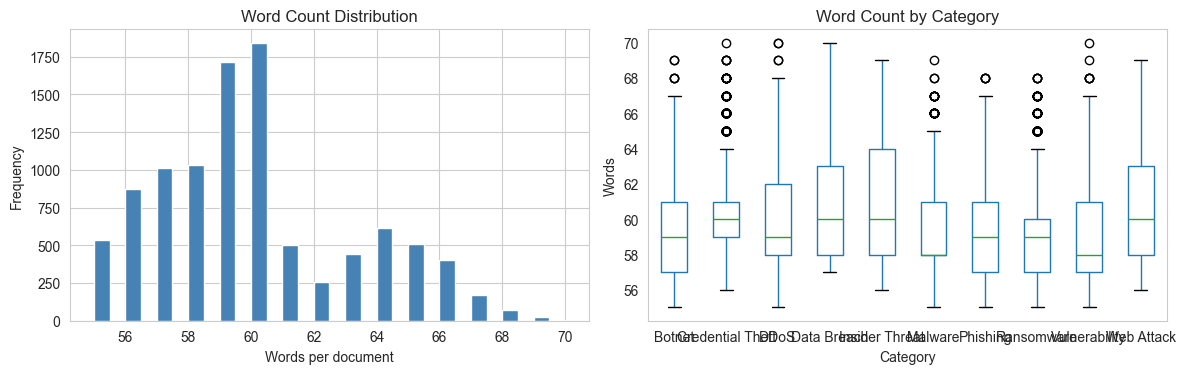

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['word_cnt'], bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Word Count Distribution')
axes[0].set_xlabel('Words per document')
axes[0].set_ylabel('Frequency')

df.boxplot(column='word_cnt', by='category', ax=axes[1], grid=False)
axes[1].set_title('Word Count by Category')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Words')
plt.suptitle('')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_text_length.png')
plt.show()

## 8. Top Terms per Class

In [15]:
def top_terms(texts, n=15):
    words = ' '.join(texts).lower().split()
    return Counter(words).most_common(n)

for cat in df['category'].unique():
    texts = df.loc[df['category'] == cat, 'text'].astype(str).tolist()
    terms = top_terms(texts, n=12)
    print(f'\n[{cat}]')
    print('  ', ', '.join([t for t, _ in terms]))


[DDoS]
   the, was, and, observed, activity, during, investigation., to, included, additional, network, ddos

[Web Attack]
   the, was, and, observed, activity, during, investigation., web, included, additional, to, attack

[Credential Theft]
   the, was, and, observed, activity, credential, additional, to, included, during, investigation., theft

[Phishing]
   the, was, and, observed, activity, during, investigation., additional, included, to, phishing, campaign

[Vulnerability]
   the, was, vulnerability, and, observed, activity, to, included, during, investigation., additional, identifier

[Botnet]
   the, was, and, observed, activity, to, during, investigation., additional, included, botnet, campaign

[Insider Threat]
   the, was, and, observed, threat, activity, during, investigation., additional, included, to, insider

[Ransomware]
   the, was, and, observed, activity, to, during, investigation., additional, included, file, ransomware

[Malware]
   the, was, and, observed, activ

## 9. Word Clouds per Category

IndexError: index 6 is out of bounds for axis 0 with size 6

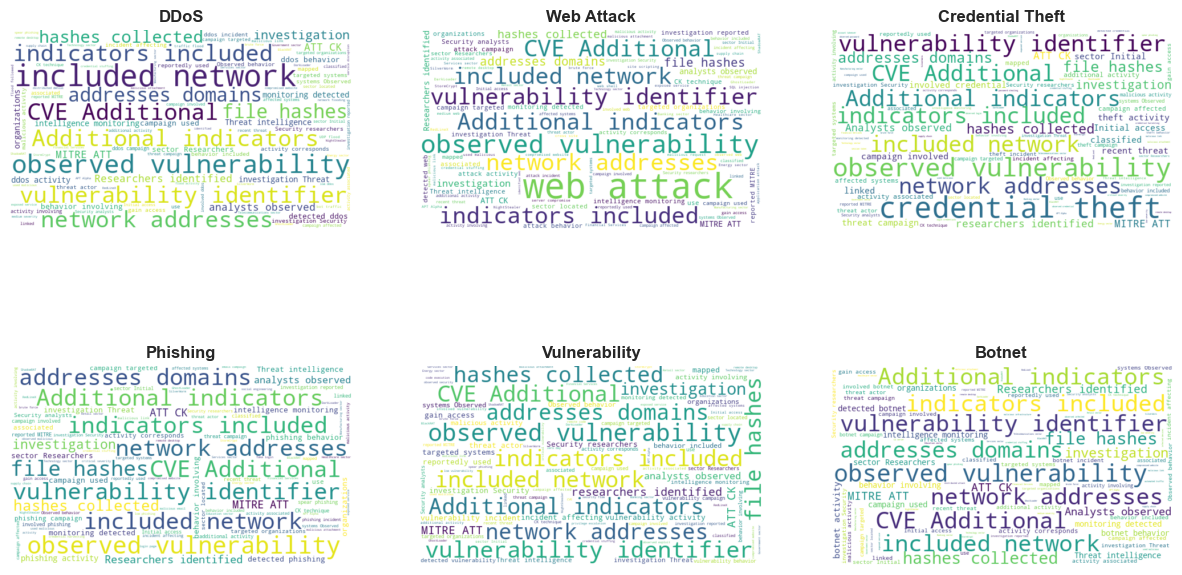

In [16]:
try:
    from wordcloud import WordCloud
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', 'wordcloud', '-q'])
    from wordcloud import WordCloud

categories = df['category'].unique()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, cat in enumerate(categories):
    text = ' '.join(df.loc[df['category'] == cat, 'text'].astype(str))
    wc = WordCloud(width=600, height=350,
                   background_color='white',
                   colormap='viridis',
                   max_words=100).generate(text)
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].set_title(cat, fontweight='bold')
    axes[i].axis('off')

for j in range(len(categories), len(axes)):
    axes[j].axis('off')

plt.suptitle('Word Clouds by Threat Category', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_wordclouds.png')
plt.show()

## 10. Key Observations

| Aspect | Finding |
|--------|---------|
| Dataset size | See Section 3 |
| Class balance | See Section 5 imbalance check |
| Temporal spread | See Section 6 monthly counts |
| Text length | See Section 7 statistics |
| Data quality | See Section 4 missing/duplicates |

<div class="callout"><b>Next step:</b> Proceed to <code>02_preprocessing.ipynb</code> to clean the text and build TF-IDF features.</div>

In [ ]:
print('EDA complete.')
print(f'Rows: {len(df)} | Categories: {df["category"].nunique()} '
      f'| Months: {df["month"].nunique()}')

---
*End of EDA notebook.*